In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Breast cancer veri seti yükleme
from sklearn.datasets import load_breast_cancer

In [2]:
import warnings

warnings.filterwarnings('ignore')

Veri Çerçevesi Oluşturma ve DataFrame Dönüşümü

In [3]:
import numpy as np

In [4]:
data = load_breast_cancer()

In [5]:
print(type(data))

<class 'sklearn.utils._bunch.Bunch'>


In [6]:
data.target_names

array(['malignant', 'benign'], dtype='<U9')

In [7]:
data.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [8]:
#Veri çerçevesi oluşturma
#Özellikler ve hedef değişlenlerine ayırma ve data frame oluşturma
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")
#İlk 5 satırı görüntüleme
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Veri Tipi Genel Bilgisi

In [9]:
print("Hedef sınıf adet dağılımı:")
print(y.value_counts())
print("Hedef dağılım oranı:")
print(y.value_counts(normalize=True))

Hedef sınıf adet dağılımı:
target
1    357
0    212
Name: count, dtype: int64
Hedef dağılım oranı:
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


In [10]:
#Veri tipi genel bilgi
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

Missing Value Analizi

In [11]:
#Missing value analizi
X.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

In [12]:
#Veri setinde missing value olmadığı için doldurma yöntemi uygulanmadı.
#Eğer missing value olsaydı aşağıdaki kod ile uygulanacaktı.
#from sklearn.impute import SimpleImputer
#imputer = SimpleImputer(strategy='median')

Outlier Hesaplama

IQR Yöntemi

In [13]:
#IQR Yöntemi ile her sütun için outlier analizi
def detect_outliers_iqr(df):
    """Outlier hesaplama - IQR"""
    outlier_info = {}
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Outlier'ları bul
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_info[col] = {
            "Q1": round(Q1, 3),
            "Q3": round(Q3, 3),
            "IQR": round(IQR, 3),
            "Alt Sınır": round(lower_bound, 3),
            "Üst Sınır": round(upper_bound, 3),
            "Outlier Sayısı": len(outliers),
            "Outlier (%)": round(100 * len(outliers) / len(df), 3)
        }
    return pd.DataFrame(outlier_info).T

outlier_report = detect_outliers_iqr(X)
outlier_report_sort = outlier_report.sort_values(by="Outlier Sayısı", ascending=False)

print("IQR Yöntemi ile Hesaplanan En Çok Outlier İçeren 10 Özellik:")
print(outlier_report.sort_values("Outlier Sayısı", ascending=False).head(10))

IQR Yöntemi ile Hesaplanan En Çok Outlier İçeren 10 Özellik:
                              Q1        Q3      IQR  Alt Sınır  Üst Sınır  \
area error                17.850    45.190   27.340    -23.160     86.200   
radius error               0.232     0.479    0.246     -0.137      0.849   
perimeter error            1.606     3.357    1.751     -1.020      5.984   
worst area               515.300  1084.000  568.700   -337.750   1937.050   
smoothness error           0.005     0.008    0.003      0.001      0.013   
fractal dimension error    0.002     0.005    0.002     -0.001      0.008   
compactness error          0.013     0.032    0.019     -0.016      0.062   
symmetry error             0.015     0.023    0.008      0.003      0.036   
mean area                420.300   782.700  362.400   -123.300   1326.300   
worst fractal dimension    0.071     0.092    0.021      0.041      0.123   

                         Outlier Sayısı  Outlier (%)  
area error                         6

In [14]:
# Tüm özelliklere ait outlier bilgisinin yüksekten aza sıralanması
outlier_report_sort

,Q1,Q3,IQR,Alt Sınır,Üst Sınır,Outlier Sayısı,Outlier (%)
area error,17.850,45.190,27.340,-23.160,86.200,65.0,11.424
radius error,0.232,0.479,0.246,-0.137,0.849,38.0,6.678
perimeter error,1.606,3.357,1.751,-1.020,5.984,38.0,6.678
worst area,515.300,1084.000,568.700,-337.750,1937.050,35.0,6.151
smoothness error,0.005,0.008,0.003,0.001,0.013,30.0,5.272
fractal dimension error,0.002,0.005,0.002,-0.001,0.008,28.0,4.921
compactness error,0.013,0.032,0.019,-0.016,0.062,28.0,4.921
symmetry error,0.015,0.023,0.008,0.003,0.036,27.0,4.745
mean area,420.300,782.700,362.400,-123.300,1326.300,25.0,4.394
worst fractal dimension,0.071,0.092,0.021,0.041,0.123,24.0,4.218


Z-Score Yöntemi

In [15]:
#Z-Score Yöntemi ile her sütun için outlier analizi
from scipy import stats

mutlak_z_score_degeri = np.abs(stats.zscore(X))
esik_deger = 3
outlier_mask = (mutlak_z_score_degeri > esik_deger)

z_outliers_per_col = outlier_mask.sum(axis=0)
z_outliers_df = pd.Series(z_outliers_per_col, index=X.columns)

print("Z-score Yöntemi ile En Çok Outlier İçeren 10 Özellik:")
print(z_outliers_df.sort_values(ascending=False).head(10))

# Toplam outlier satırları (herhangi bir sütunda outlier olan)
rows_with_outlier = outlier_mask.any(axis=1).sum()
print(f"\nEn az bir sütunda outlier içeren satır sayısı: {rows_with_outlier} / {len(X)}")
print(f"Yüzde: %{100*rows_with_outlier/len(X):.2f}")

Z-score Yöntemi ile En Çok Outlier İçeren 10 Özellik:
compactness error          12
symmetry error             11
worst area                 10
fractal dimension error    10
worst compactness          10
mean compactness            9
texture error               9
worst fractal dimension     9
worst symmetry              9
mean concavity              9
dtype: int64

En az bir sütunda outlier içeren satır sayısı: 74 / 569
Yüzde: %13.01


In [16]:
# Outlier sayıları arasındaki karşılaştırma
comparison = pd.DataFrame({
    "IQR Outlier": outlier_report["Outlier Sayısı"].astype(int),
    "Z-score Outlier": z_outliers_df
})
comparison["Fark"] = comparison["IQR Outlier"] - comparison["Z-score Outlier"]

print("Tüm Özellikler için IQR vs Z-score Karşılaştırması:")
print(comparison.sort_values("Fark", ascending=False))

Tüm Özellikler için IQR vs Z-score Karşılaştırması:
                         IQR Outlier  Z-score Outlier  Fark
area error                        65                6    59
radius error                      38                7    31
perimeter error                   38                8    30
worst area                        35               10    25
smoothness error                  30                7    23
fractal dimension error           28               10    18
mean area                         25                8    17
concavity error                   22                6    16
compactness error                 28               12    16
symmetry error                    27               11    16
worst fractal dimension           24                9    15
worst symmetry                    23                9    14
concave points error              19                6    13
texture error                     20                9    11
worst radius                      17            

In [17]:
print(comparison.sort_values("IQR Outlier", ascending=False))

                         IQR Outlier  Z-score Outlier  Fark
area error                        65                6    59
radius error                      38                7    31
perimeter error                   38                8    30
worst area                        35               10    25
smoothness error                  30                7    23
fractal dimension error           28               10    18
compactness error                 28               12    16
symmetry error                    27               11    16
mean area                         25                8    17
worst fractal dimension           24                9    15
worst symmetry                    23                9    14
concavity error                   22                6    16
texture error                     20                9    11
concave points error              19                6    13
mean concavity                    18                9     9
worst radius                      17    

 IQR daha agresif (daha çok outlier yakalar),
 Z-score sadece aşırı uçtaki değerleri yakalar. -- Yorum eklenecek.

Keşifsel Veri Analizi - İstatistiksel Özellikler

In [18]:
statistics = X.describe().T

statistics_summary = pd.DataFrame({
    "Mean": X.mean(),
    "Median": X.median(),
    "Std": X.std(),
    "Minimum": X.min(),
    "Q1 (25%)": X.quantile(0.25),
    "Q3 (75%)": X.quantile(0.75),
    "Maximum": X.max(),
}).round(3)

print("İstatistiksel özet: ")
print(statistics_summary)

İstatistiksel özet: 
                            Mean   Median      Std  Minimum  Q1 (25%)  \
mean radius               14.127   13.370    3.524    6.981    11.700   
mean texture              19.290   18.840    4.301    9.710    16.170   
mean perimeter            91.969   86.240   24.299   43.790    75.170   
mean area                654.889  551.100  351.914  143.500   420.300   
mean smoothness            0.096    0.096    0.014    0.053     0.086   
mean compactness           0.104    0.093    0.053    0.019     0.065   
mean concavity             0.089    0.062    0.080    0.000     0.030   
mean concave points        0.049    0.034    0.039    0.000     0.020   
mean symmetry              0.181    0.179    0.027    0.106     0.162   
mean fractal dimension     0.063    0.062    0.007    0.050     0.058   
radius error               0.405    0.324    0.277    0.112     0.232   
texture error              1.217    1.108    0.552    0.360     0.834   
perimeter error            2.8

In [19]:
statistics_summary.to_excel("Statistics_summary.xlsx")

Korelasyon Matrisi

In [20]:
# Hedeflere göre açısından hangi değerler arasında en büyük farklar var?
X_with_target = X.copy()
X_with_target["target"] = y.map({0: "malignant", 1: "benign"})

class_means = X_with_target.groupby("target").mean().T
class_means["Fark"] = class_means["malignant"] - class_means["benign"]

# En çok ayrışan 10 özellik
print("İki sınıf arasındaki ortalama farkı en büyük 10 özellik:")
print(class_means.sort_values("Fark", ascending=False).head(10).round(3))


İki sınıf arasındaki ortalama farkı en büyük 10 özellik:
target            benign  malignant     Fark
worst area       558.899   1422.286  863.387
mean area        462.790    978.376  515.586
worst perimeter   87.006    141.370   54.364
area error        21.135     72.672   51.537
mean perimeter    78.075    115.365   37.290
worst radius      13.380     21.135    7.755
worst texture     23.515     29.318    5.803
mean radius       12.147     17.463    5.316
mean texture      17.915     21.605    3.690
perimeter error    2.000      4.324    2.324


In [21]:
# Pearson korelasyon matrisi
corr_matrix = X.corr(method="pearson").round(3)

print(f"Korelasyon matrisi şekli: {corr_matrix.shape}")

print("İlk 5×5 veri")
print(corr_matrix.iloc[:5, :5].round(3))

Korelasyon matrisi şekli: (30, 30)
İlk 5×5 veri
                 mean radius  mean texture  mean perimeter  mean area  \
mean radius            1.000         0.324           0.998      0.987   
mean texture           0.324         1.000           0.330      0.321   
mean perimeter         0.998         0.330           1.000      0.987   
mean area              0.987         0.321           0.987      1.000   
mean smoothness        0.171        -0.023           0.207      0.177   

                 mean smoothness  
mean radius                0.171  
mean texture              -0.023  
mean perimeter             0.207  
mean area                  0.177  
mean smoothness            1.000  


In [22]:
corr_matrix.to_excel("Korelasyon Matrisi.xlsx")

Heatmap Görselleştirme

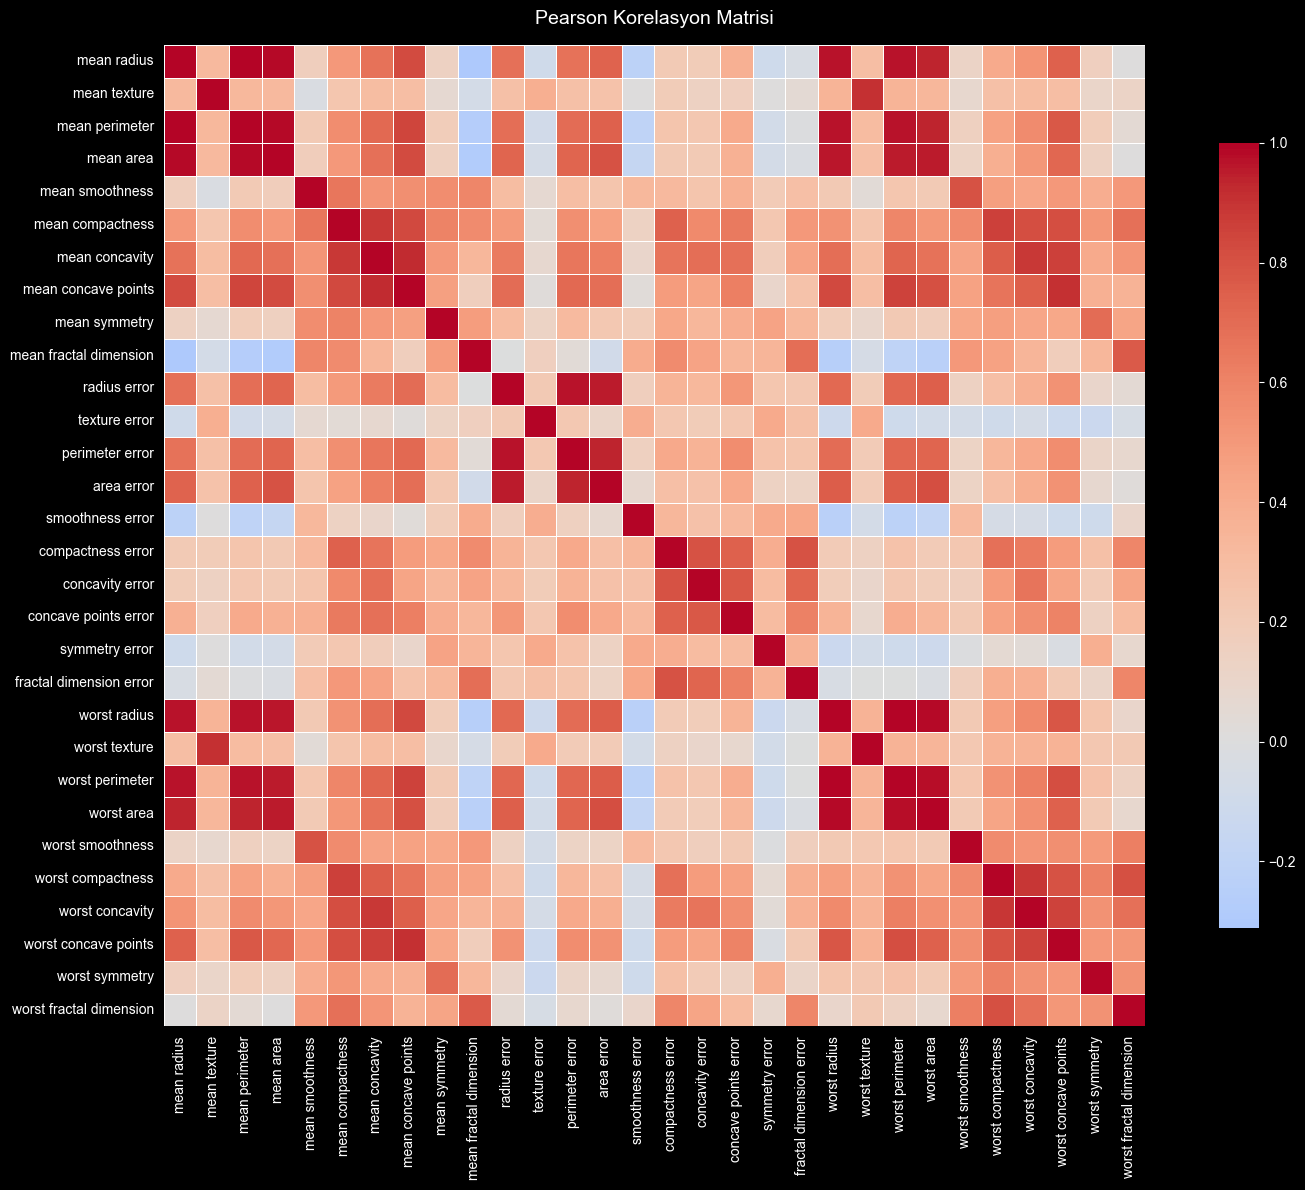

In [23]:
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix,
            cmap="coolwarm",
            center=0,
            annot=False,
            square=True,
            cbar_kws={"shrink": 0.8},
            linewidths=0.5)
plt.title("Pearson Korelasyon Matrisi", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

En yüksek korelasyon çiftlerini bulma

In [24]:
corr_unstacked = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack().reset_index()

corr_unstacked.columns = ["Özellik 1", "Özellik 2", "Korelasyon"]
corr_unstacked["Mutlak"] = corr_unstacked["Korelasyon"].abs()

# En yüksek 10 korelasyon
top_corr = corr_unstacked.sort_values("Mutlak", ascending=False).head(3)
print("En yüksek korelasyonlu 3 özellik çifti:")
print(top_corr[["Özellik 1", "Özellik 2", "Korelasyon"]].to_string(index=False))

En yüksek korelasyonlu 3 özellik çifti:
     Özellik 1       Özellik 2  Korelasyon
   mean radius  mean perimeter       0.998
  worst radius worst perimeter       0.994
mean perimeter       mean area       0.987


En ayırt edici 6 özellik

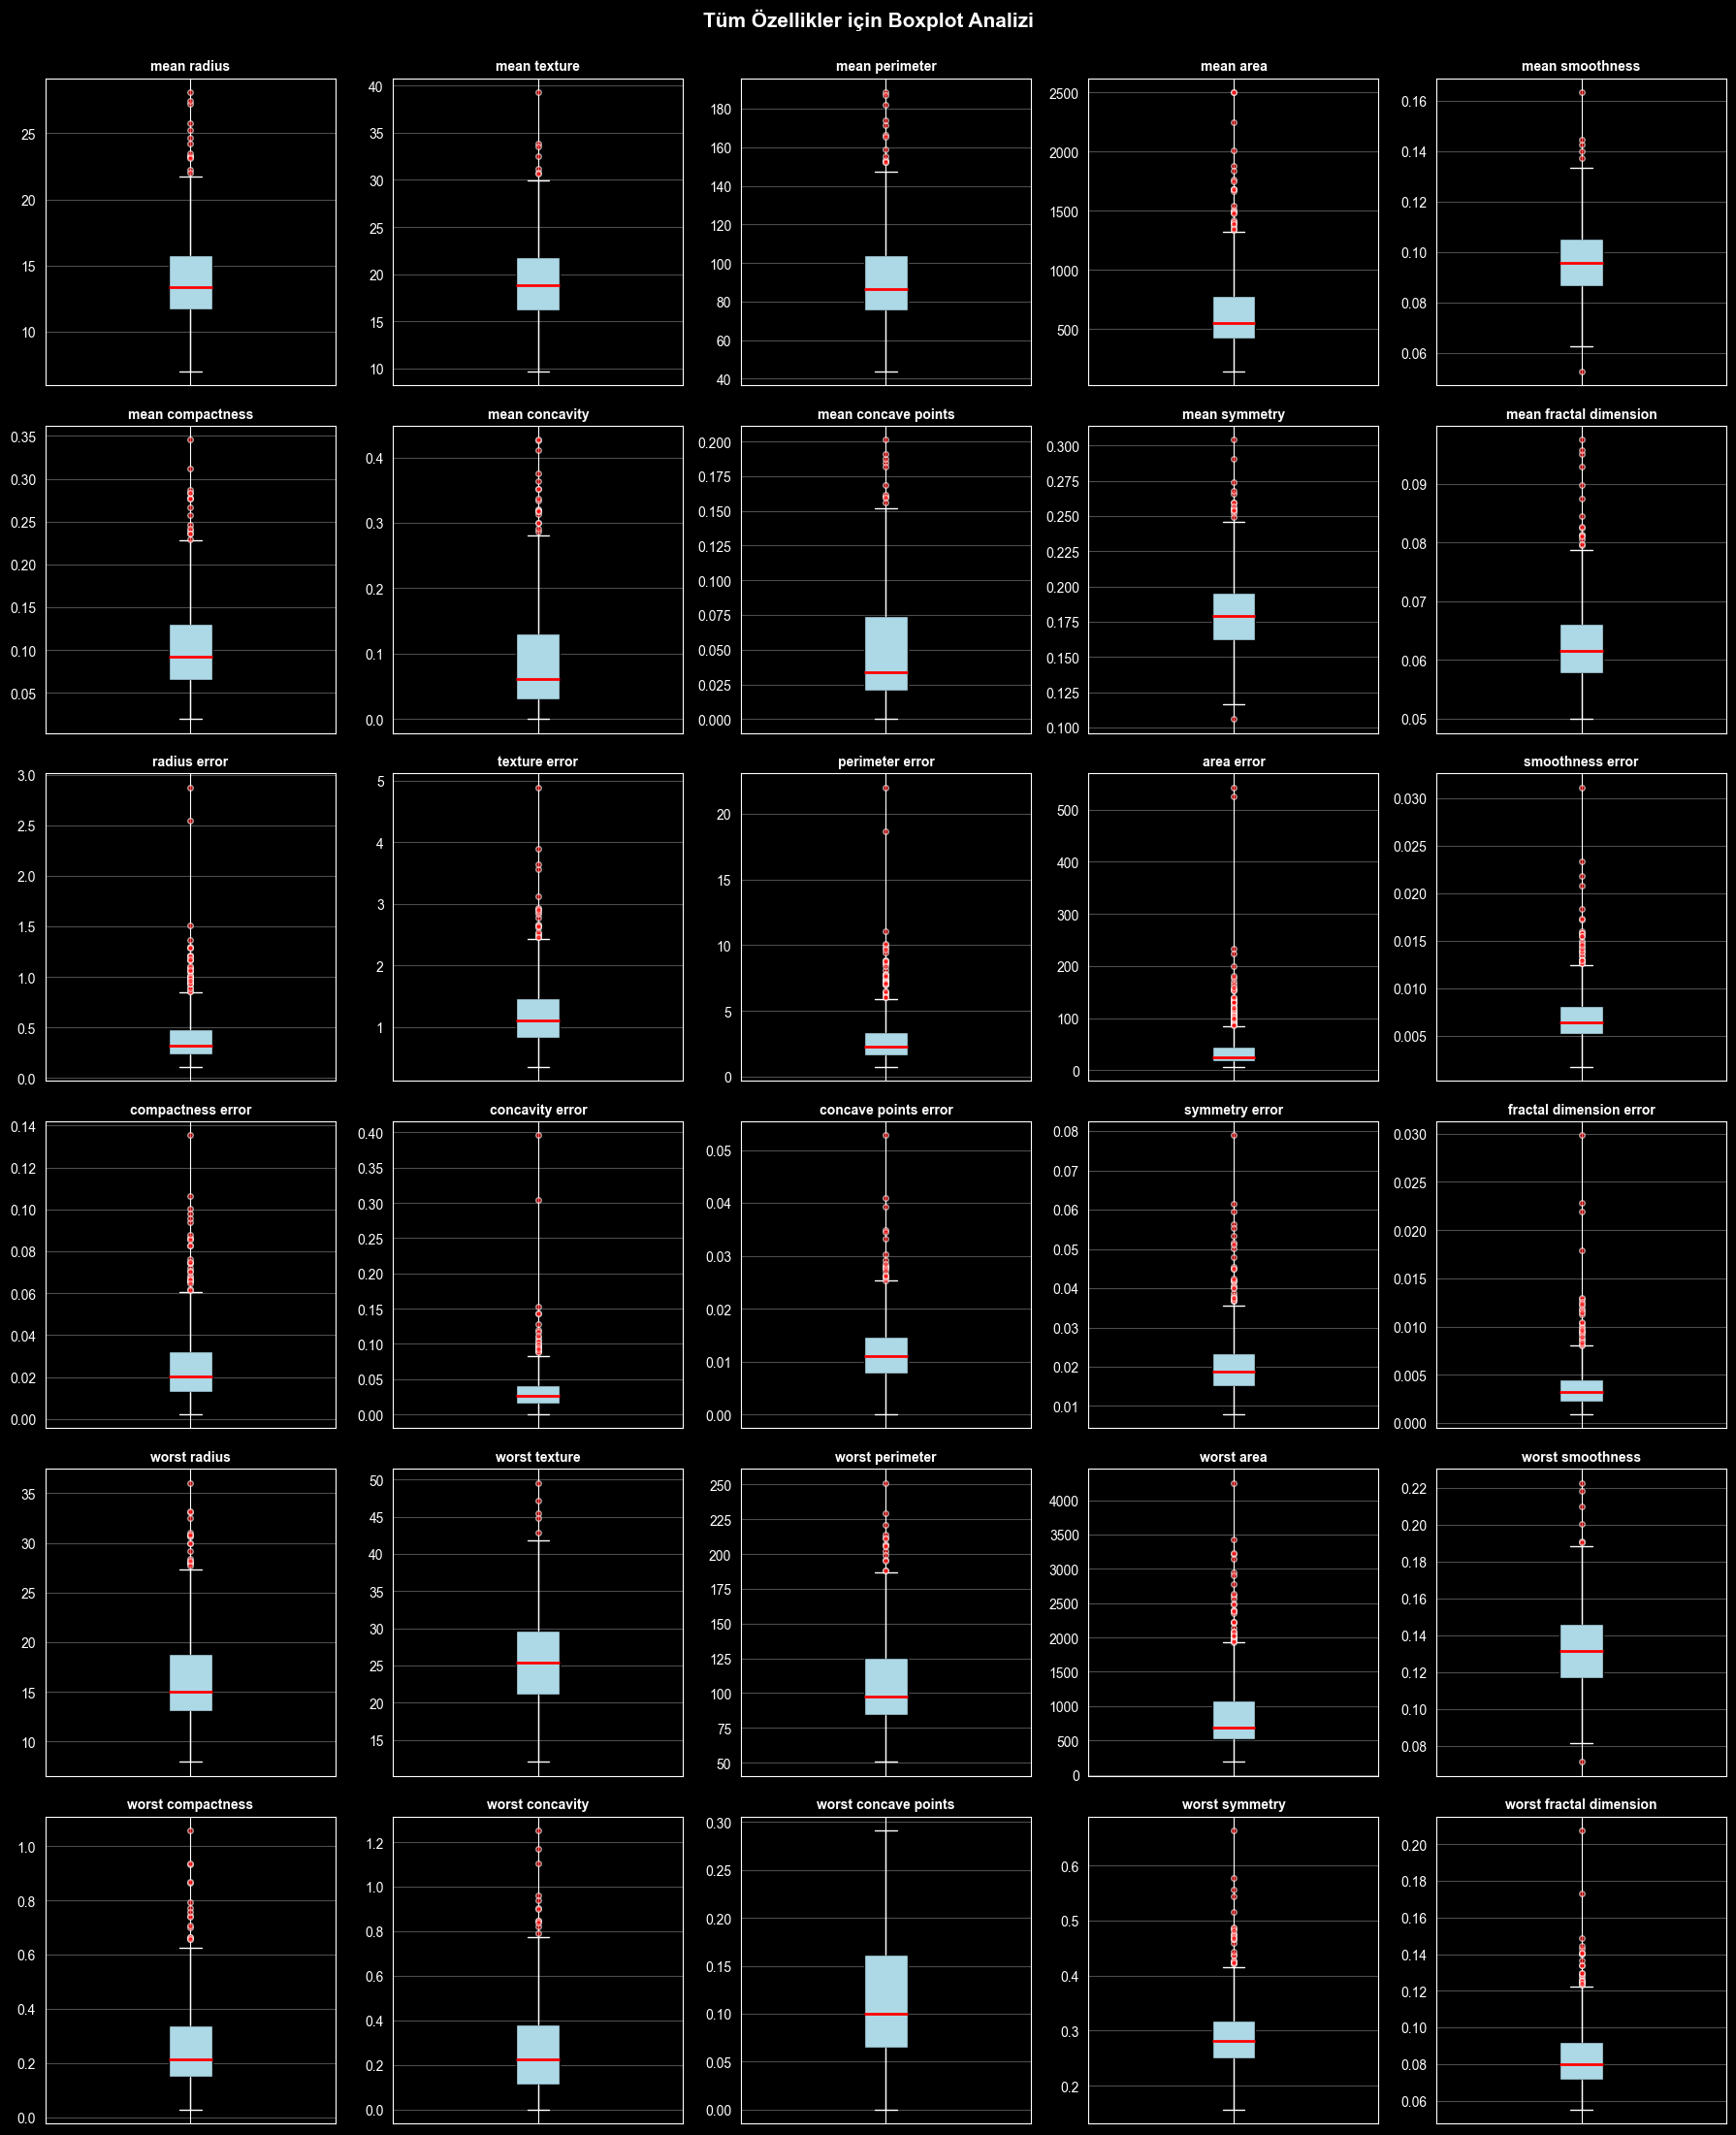

In [25]:
fig, axes = plt.subplots(6, 5, figsize=(18, 22))
axes = axes.flatten()

for i, col in enumerate(X.columns):
    axes[i].boxplot(X[col].values, vert=True, patch_artist=True,
                     boxprops=dict(facecolor="lightblue", edgecolor="black"),
                     medianprops=dict(color="red", linewidth=2),
                     flierprops=dict(marker="o", markerfacecolor="red",
                                     markersize=4, alpha=0.6))
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].tick_params(axis='x', which="both", bottom=False, labelbottom=False)
    axes[i].grid(axis='y', alpha=0.3)

plt.suptitle("Tüm Özellikler için Boxplot Analizi",
             fontsize=15, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()

Hedefle en korelasyonlu özellik:

Hedef değişkenle en yüksek korelasyonu olan 10 özellik:
                      Korelasyon
worst concave points      -0.794
worst perimeter           -0.783
mean concave points       -0.777
worst radius              -0.776
mean perimeter            -0.743
worst area                -0.734
mean radius               -0.730
mean area                 -0.709
mean concavity            -0.696
worst concavity           -0.660


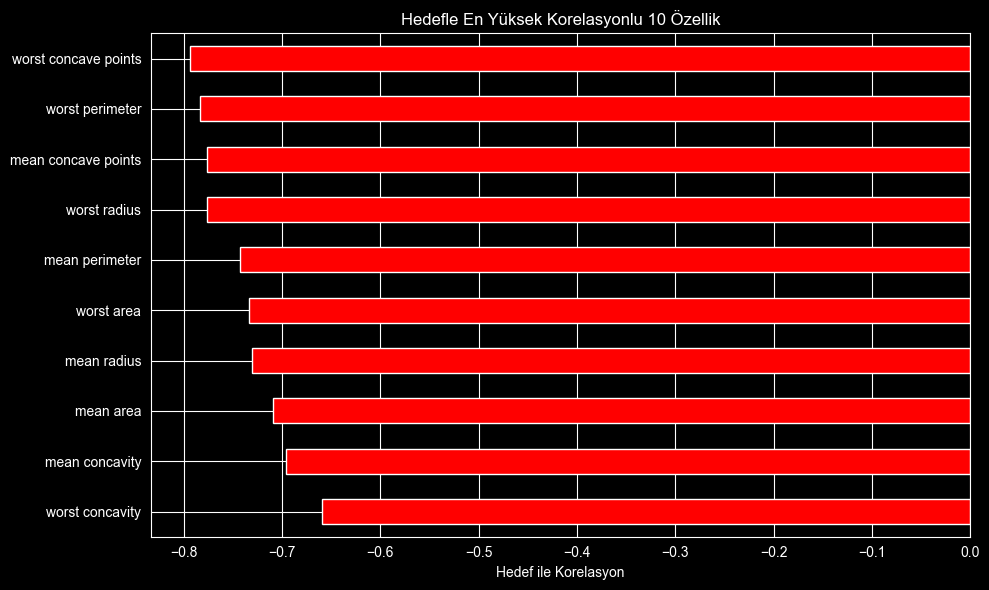

In [26]:
X_y = X.copy()
X_y["target"] = y
target_corr = X_y.corr()["target"].drop("target").sort_values(key=abs, ascending=False)

print("Hedef değişkenle en yüksek korelasyonu olan 10 özellik:")
print(target_corr.head(10).to_frame("Korelasyon").round(3))


fig, axes = plt.subplots(figsize=(10, 6))
colors = ["red" if c < 0 else "blue" for c in target_corr.head(10)]
target_corr.head(10).plot(kind='barh', axes=axes, color=colors)
axes.set_xlabel("Hedef ile Korelasyon")
axes.set_title("Hedefle En Yüksek Korelasyonlu 10 Özellik")
axes.invert_yaxis()
plt.tight_layout()
plt.show()

StandardScaler ile Veriyi Ölçeklendirme

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print("StandardScaler ile ölçeklendirilerek X_scaled oluşturuldu.")
print("Doğrulama Kontrolleri:")
print(f"Tüm sütunların ortalaması: {X_scaled.mean().abs().max():.2e} (~0)")
print(f"Tüm sütunların std değeri: {X_scaled.std().mean():.4f} (~1)")


StandardScaler ile ölçeklendirilerek X_scaled oluşturuldu.
Doğrulama Kontrolleri:
Tüm sütunların ortalaması: 8.37e-16 (~0)
Tüm sütunların std değeri: 1.0009 (~1)


Verinin Bölünmesi

In [28]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.125,
    stratify=y_temp,
    random_state=42
)

print("Bölme işlemi sonrasında veri setleri:")
print(f"Train:      {X_train.shape[0]:3d} örnek (%{100*X_train.shape[0]/len(X):.1f})")
print(f"Validation: {X_val.shape[0]:3d} örnek (%{100*X_val.shape[0]/len(X):.1f})")
print(f"Test:       {X_test.shape[0]:3d} örnek (%{100*X_test.shape[0]/len(X):.1f})")
print(f"Toplam:     {X_train.shape[0]+X_val.shape[0]+X_test.shape[0]:3d} örnek")

Bölme işlemi sonrasında veri setleri:
Train:      398 örnek (%69.9)
Validation:  57 örnek (%10.0)
Test:       114 örnek (%20.0)
Toplam:     569 örnek


Stratify Kontrolü

In [29]:
def class_distribution(y_subset, name):
    counts = y_subset.value_counts()
    pct = (counts / len(y_subset) * 100).round(1)
    return pd.DataFrame({
        "Sayı": counts,
        "Yüzde": "%" +" "+ pct.astype(str)
    }).rename_axis(name)

print(class_distribution(y, "Tüm"))
print(class_distribution(y_train, "Train"))
print(class_distribution(y_val, "Val"))
print(class_distribution(y_test, "Test"))



     Sayı   Yüzde
Tüm              
1     357  % 62.7
0     212  % 37.3
       Sayı   Yüzde
Train              
1       249  % 62.6
0       149  % 37.4
     Sayı   Yüzde
Val              
1      36  % 63.2
0      21  % 36.8
      Sayı   Yüzde
Test              
1       72  % 63.2
0       42  % 36.8


StandardScaler ile Verinin Ölçeklendirilmesi

In [30]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns=X.columns,
    index=X_train.index
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X.columns,
    index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

print("Scaling uygulama sonrasında setlerdeki datanın kontrolü:")
print(f'X_train_scaled:  {X_train_scaled.shape}')
print(f'X_val_scaled:    {X_val_scaled.shape}')
print(f'X_test_scaled:   {X_test_scaled.shape}')
print()
print("Train setinde ortalama ve std kontrolü: Train\'de mean ≈ 0, std ≈ 1:")
print(f"Train ortalama: {X_train_scaled.mean().abs().max():.2e} ~0")
print(f"Train std:  {X_train_scaled.std().mean():.4f} ~1")
print()
print("Validasyon ve Test setlerinde ortalama ve std kontrolü:")
print(f"Val ortalama: {X_val_scaled.mean().abs().max():.3f}")
print(f"Validasyon std: {X_val_scaled.std().mean():.3f}")
print(f"Test ortalama: {X_test_scaled.mean().abs().max():.3f}")
print(f"Test std: {X_test_scaled.std().mean():.3f}")

Scaling uygulama sonrasında setlerdeki datanın kontrolü:
X_train_scaled:  (398, 30)
X_val_scaled:    (57, 30)
X_test_scaled:   (114, 30)

Train setinde ortalama ve std kontrolü: Train'de mean ≈ 0, std ≈ 1:
Train ortalama: 1.48e-15 ~0
Train std:  1.0013 ~1

Validasyon ve Test setlerinde ortalama ve std kontrolü:
Val ortalama: 0.255
Validasyon std: 0.866
Test ortalama: 0.144
Test std: 0.935


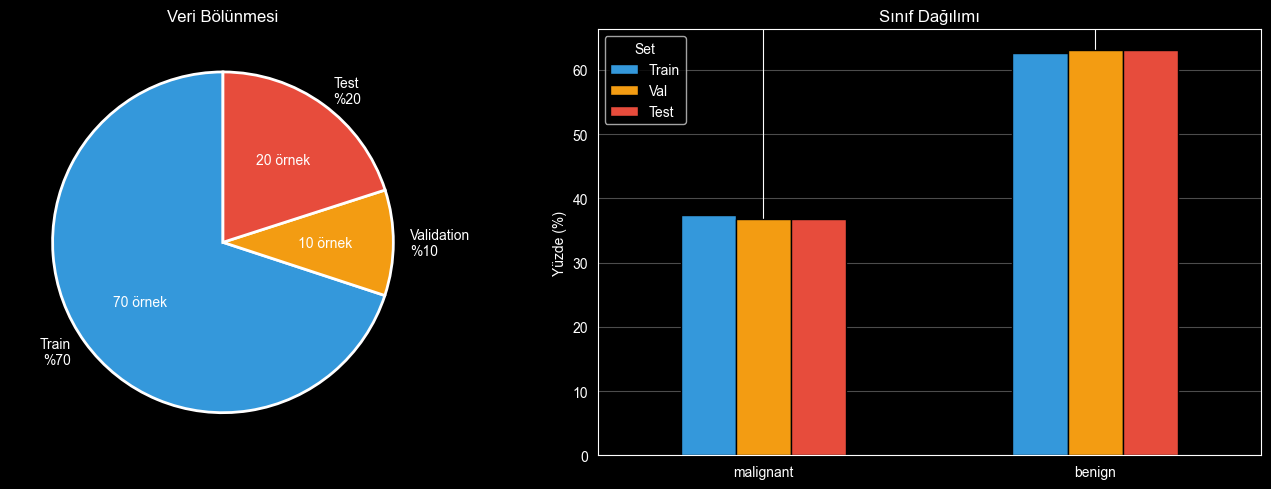

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sizes = [X_train.shape[0], X_val.shape[0], X_test.shape[0]]
labels = ["Train\n%70", "Validation\n%10", "Test\n%20"]
colors = ["#3498db", "#f39c12", "#e74c3c"]

axes[0].pie(sizes, labels=labels, colors=colors, autopct="%1.0f örnek",
            startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[0].set_title("Veri Bölünmesi")


df_dist = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Val": y_val.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()
}) * 100

df_dist.index = ["malignant", "benign"]
df_dist.plot(kind="bar", ax=axes[1], color=["#3498db", "#f39c12", "#e74c3c"],
             edgecolor="black")
axes[1].set_title("Sınıf Dağılımı")
axes[1].set_ylabel("Yüzde (%)")
axes[1].set_xticklabels(["malignant", "benign"], rotation=0)
axes[1].legend(title="Set")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Principal Component Analysis - PCA - Temel Bileşenler Analizi

Tüm bileşenleri çıkarıp explained variance hesaplaması

In [32]:
from sklearn.decomposition import PCA

# Tüm bileşenler çıkarılır.
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Explained variance ratio = her bileşenin verinin yüzde kaçını açıkladığı oranı
evr = pca_full.explained_variance_ratio_
cumulative_evr = np.cumsum(evr)

print(f"Toplam {len(evr)} temel bileşen üretildi.")
print("İlk 10 bileşen:")
for i in range(10):
    print(f"  PC{i+1}: %{100*evr[i]:.2f} açıklama, kümülatif %{100*cumulative_evr[i]:.2f}")

Toplam 30 temel bileşen üretildi.
İlk 10 bileşen:
  PC1: %44.92 açıklama, kümülatif %44.92
  PC2: %18.90 açıklama, kümülatif %63.81
  PC3: %9.36 açıklama, kümülatif %73.17
  PC4: %6.69 açıklama, kümülatif %79.86
  PC5: %5.43 açıklama, kümülatif %85.28
  PC6: %3.90 açıklama, kümülatif %89.19
  PC7: %2.20 açıklama, kümülatif %91.38
  PC8: %1.55 açıklama, kümülatif %92.93
  PC9: %1.29 açıklama, kümülatif %94.22
  PC10: %1.18 açıklama, kümülatif %95.40


Bileşen sayısı seçimi

In [33]:
# EVR ortalamasından büyük olanların seçilmesi
mean_evr = evr.mean()
n_components_pca = np.sum(evr > mean_evr)

print(f"Tüm bileşenlerin ortalama açıklaması: %{100*mean_evr:.2f}")
print(f"Bu ortalamayı geçen bileşen sayısı: {n_components_pca}")
print(f"Bu bileşenler birlikte verinin %{100*cumulative_evr[n_components_pca-1]:.2f}\'ini açıklıyor.")

Tüm bileşenlerin ortalama açıklaması: %3.33
Bu ortalamayı geçen bileşen sayısı: 6
Bu bileşenler birlikte verinin %89.19'ini açıklıyor.


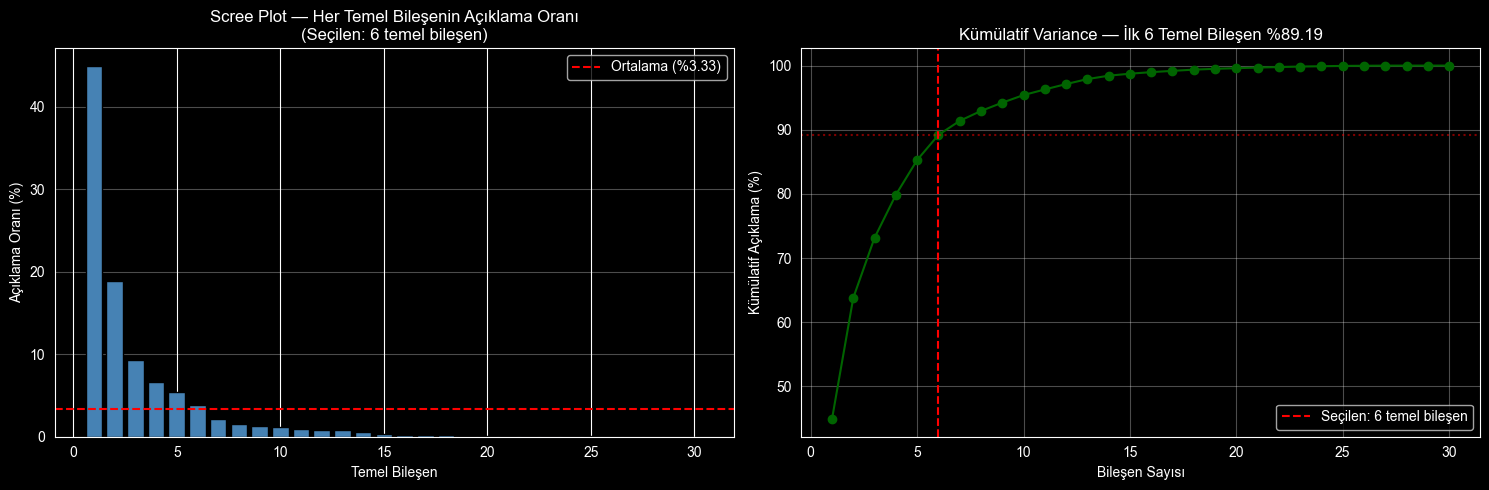

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Grafik: Her bileşenin açıklama oranı (Scree plot)
axes[0].bar(range(1, len(evr)+1), evr*100, color="steelblue", edgecolor="black")
axes[0].axhline(y=mean_evr*100, color='red', linestyle='--',
                label=f"Ortalama (%{100*mean_evr:.2f})")
axes[0].set_xlabel("Temel Bileşen")
axes[0].set_ylabel("Açıklama Oranı (%)")
axes[0].set_title(f"Scree Plot — Her Temel Bileşenin Açıklama Oranı\n(Seçilen: {n_components_pca} temel bileşen)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# 2. Grafik: Kümülatif açıklama
axes[1].plot(range(1, len(evr)+1), cumulative_evr*100, marker="o", color="darkgreen")
axes[1].axvline(x=n_components_pca, color="red", linestyle="--",
                label=f"Seçilen: {n_components_pca} temel bileşen")
axes[1].axhline(y=cumulative_evr[n_components_pca-1]*100, color='red', linestyle=':', alpha=0.5)
axes[1].set_xlabel("Bileşen Sayısı")
axes[1].set_ylabel("Kümülatif Açıklama (%)")
axes[1].set_title(f"Kümülatif Variance — İlk {n_components_pca} Temel Bileşen %{100*cumulative_evr[n_components_pca-1]:.2f}")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

PCA Seçilen Bileşenlere Uygulanması

In [35]:
# Seçilen sayıda PCA modeli kur
pca = PCA(n_components=n_components_pca)
pca.fit(X_train_scaled)  # train'de fit

# Her sete transform uygula
X_train_pca = pca.transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Temel Bileşen Analizi Sonucu: {X.shape[1]} bileşenden → {n_components_pca} temel bileşene")
print(f"Train PCA şekli: {X_train_pca.shape}")
print(f"Val PCA şekli:   {X_val_pca.shape}")
print(f"Test PCA şekli:  {X_test_pca.shape}")
print()
print(f"Bu {n_components_pca} temel bileşen, verideki bilginin %{100*pca.explained_variance_ratio_.sum():.2f}\'ini saklıyor.")

Temel Bileşen Analizi Sonucu: 30 bileşenden → 6 temel bileşene
Train PCA şekli: (398, 6)
Val PCA şekli:   (57, 6)
Test PCA şekli:  (114, 6)

Bu 6 temel bileşen, verideki bilginin %89.19'ini saklıyor.


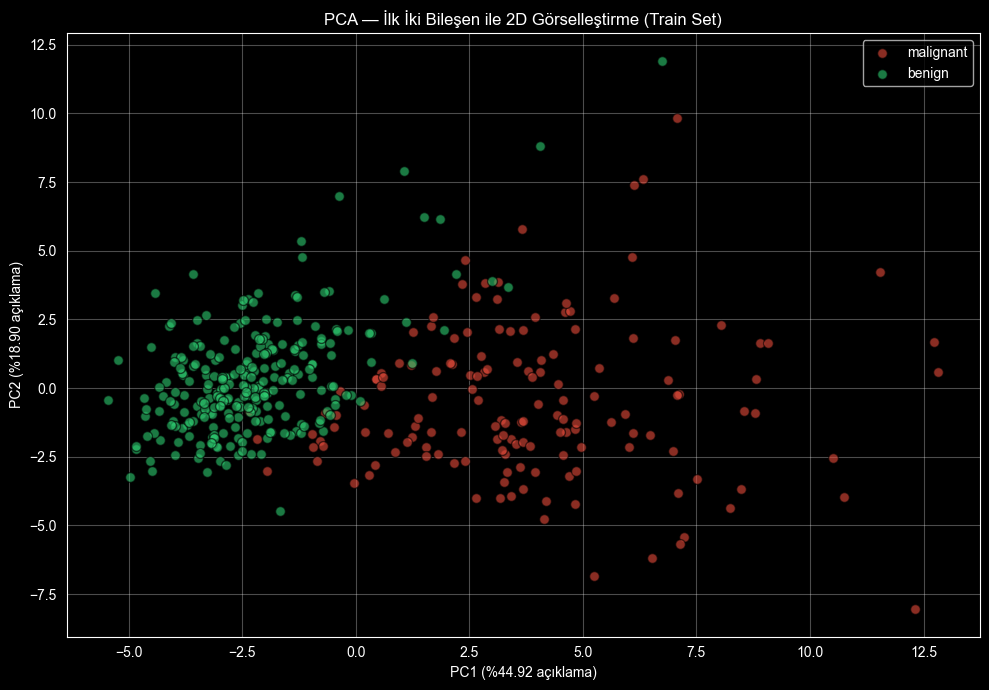

In [36]:
# İlk iki bileşen ile 2D scatter (sınıflar renkli)
fig, ax = plt.subplots(figsize=(10, 7))

colors = ["#e74c3c", "#2ecc71"]
labels = ["malignant", "benign"]

for i, label in enumerate(labels):
    mask = y_train.values == i
    ax.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1],
               c=colors[i], label=label, alpha=0.6, edgecolor='black', s=50)

ax.set_xlabel(f"PC1 (%{100*pca.explained_variance_ratio_[0]:.2f} açıklama)")
ax.set_ylabel(f"PC2 (%{100*pca.explained_variance_ratio_[1]:.2f} açıklama)")
ax.set_title("PCA — İlk İki Bileşen ile 2D Görselleştirme (Train Set)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Linear Discriminant Analysis - LDA - Doğrusal Ayrıştırma Analizi

In [37]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

n_classes = len(np.unique(y_train))
n_components_lda = min(X_train_scaled.shape[1], n_classes - 1)

print(f"Sınıf sayısı: {n_classes}")
print(f"Özellik sayısı: {X_train_scaled.shape[1]}")
print(f"LDA max bileşen sayısı: min(30, {n_classes-1}) = {n_components_lda}")

print(f"Breast Cancer veri seti 2 sınıflı olduğu için maksimum {n_components_lda} bileşen üretilebilir.")

Sınıf sayısı: 2
Özellik sayısı: 30
LDA max bileşen sayısı: min(30, 1) = 1
Breast Cancer veri seti 2 sınıflı olduğu için maksimum 1 bileşen üretilebilir.


In [38]:
lda = LinearDiscriminantAnalysis(n_components=n_components_lda)
lda.fit(X_train_scaled, y_train)

X_train_lda = lda.transform(X_train_scaled)
X_val_lda = lda.transform(X_val_scaled)
X_test_lda = lda.transform(X_test_scaled)

print(f"LDA tamamlandı. Boyut: {X.shape[1]} → {n_components_lda}")
print(f"Train LDA şekli: {X_train_lda.shape}")
print(f"Val LDA şekli:   {X_val_lda.shape}")
print(f"Test LDA şekli:  {X_test_lda.shape}")

LDA tamamlandı. Boyut: 30 → 1
Train LDA şekli: (398, 1)
Val LDA şekli:   (57, 1)
Test LDA şekli:  (114, 1)


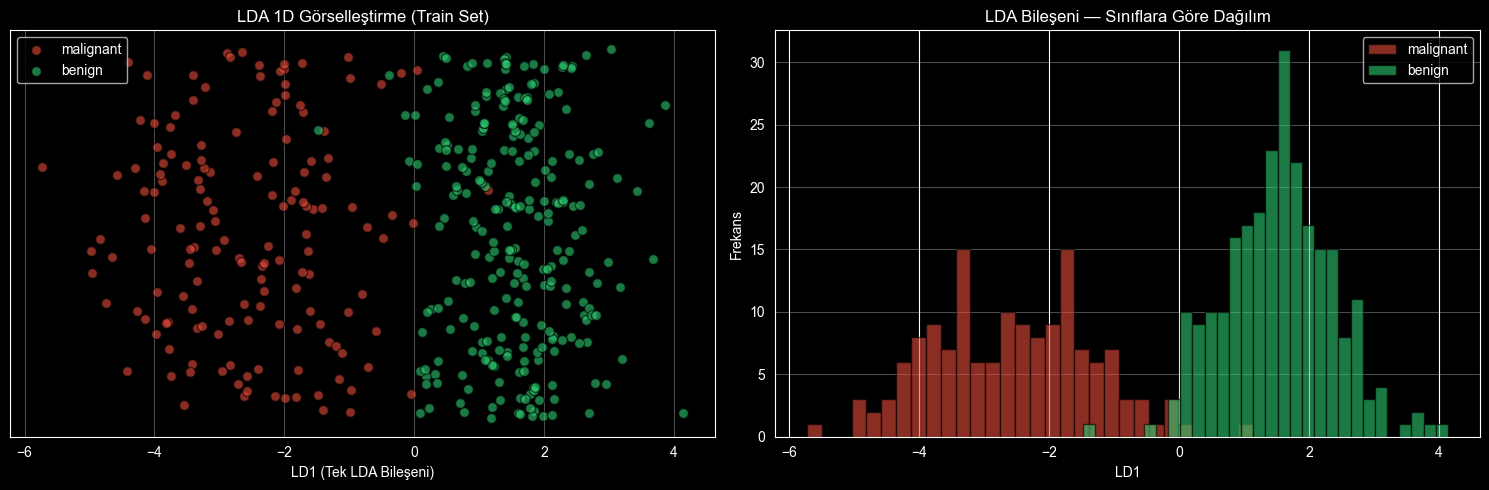

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Grafik: 1D scatter (jitter ile y eksenine yayma)
np.random.seed(0)
jitter = np.random.uniform(-0.1, 0.1, len(y_train))

for i, label in enumerate(labels):
    mask = y_train.values == i
    axes[0].scatter(X_train_lda[mask, 0], jitter[mask],
                    c=colors[i], label=label, alpha=0.6, edgecolor='black', s=50)
axes[0].set_xlabel("LD1 (Tek LDA Bileşeni)")
axes[0].set_yticks([])
axes[0].set_title("LDA 1D Görselleştirme (Train Set)")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.3)

# Sağ: Sınıflara göre LD1 dağılımı
for i, label in enumerate(labels):
    mask = y_train.values == i
    axes[1].hist(X_train_lda[mask, 0], bins=30, alpha=0.6,
                 label=label, color=colors[i], edgecolor='black')
axes[1].set_xlabel("LD1")
axes[1].set_ylabel("Frekans")
axes[1].set_title("LDA Bileşeni — Sınıflara Göre Dağılım")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
data_representations = {
    "Ham": {
        "X_train": X_train_scaled,
        "X_val":   X_val_scaled,
        "X_test":  X_test_scaled
    },
    "PCA": {
        "X_train": X_train_pca,
        "X_val":   X_val_pca,
        "X_test":  X_test_pca
    },
    "LDA": {
        "X_train": X_train_lda,
        "X_val":   X_val_lda,
        "X_test":  X_test_lda
    }
}

print("Veri temsilleri:")
for name, d in data_representations.items():
    print(f"  {name:5s}: train={d['X_train'].shape}, val={d['X_val'].shape}, test={d['X_test'].shape}")

Veri temsilleri:
  Ham  : train=(398, 30), val=(57, 30), test=(114, 30)
  PCA  : train=(398, 6), val=(57, 6), test=(114, 6)
  LDA  : train=(398, 1), val=(57, 1), test=(114, 1)


Makine Öğrenmesi Modellerinin Kurulması

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# Modellerin bir sözlükte toplanması
def get_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        "Decision Tree": DecisionTreeClassifier(
            random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),
        "XGBoost": XGBClassifier(
            n_estimators=100,
            random_state=42,
            use_label_encoder=False,
            eval_metric='logloss',
            verbosity=0
        ),
        "Gaussian NB": GaussianNB()
    }

print("Algoritmalar hazır:", list(get_models().keys()))

Algoritmalar hazır: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'Gaussian NB']


In [42]:
# Eğitilmiş model sözlüğü
trained_models = {
    "Ham": {},
    "PCA": {},
    "LDA": {}
}

# Her veri seti için
for repr_name, repr_data in data_representations.items():
    print(f"{repr_name} veri ile eğitim:")
    X_tr = repr_data['X_train']
    #Modeller
    models = get_models()
    for model_name, model in models.items():
        model.fit(X_tr, y_train)
        trained_models[repr_name][model_name] = model
        print(f"  {model_name} eğitildi.")

print("Toplam 15 model eğitildi.")

Ham veri ile eğitim:
  Logistic Regression eğitildi.
  Decision Tree eğitildi.
  Random Forest eğitildi.
  XGBoost eğitildi.
  Gaussian NB eğitildi.
PCA veri ile eğitim:
  Logistic Regression eğitildi.
  Decision Tree eğitildi.
  Random Forest eğitildi.
  XGBoost eğitildi.
  Gaussian NB eğitildi.
LDA veri ile eğitim:
  Logistic Regression eğitildi.
  Decision Tree eğitildi.
  Random Forest eğitildi.
  XGBoost eğitildi.
  Gaussian NB eğitildi.
Toplam 15 model eğitildi.


Validasyon Performanslarının Ölçülmesi

In [43]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)

def evaluate_model(model, X_eval, y_eval):
    """Bir modelin 5 metriğini hesapla ve döndür."""
    y_pred = model.predict(X_eval)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_eval)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba = model.decision_function(X_eval)
    else:
        y_proba = y_pred

    return {
        "Accuracy":  accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred),
        "Recall":    recall_score(y_eval, y_pred),
        "F1":        f1_score(y_eval, y_pred),
        "ROC-AUC":   roc_auc_score(y_eval, y_proba)
    }

In [44]:
results = []
for repr_name, repr_data in data_representations.items():
    X_v = repr_data["X_val"]
    for model_name, model in trained_models[repr_name].items():
        metrics = evaluate_model(model, X_v, y_val)
        results.append({
            "Model": model_name,
            "Veri": repr_name,
            **metrics
        })

results_df = pd.DataFrame(results)

results_df_sorted = results_df.sort_values('F1', ascending=False).reset_index(drop=True)

for col in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    results_df_sorted[col] = results_df_sorted[col].round(4)

print("Validasyon Karşılaştırma Tablosu (F1 e göre azalan):")

print(results_df_sorted.to_string(index=False))

Validasyon Karşılaştırma Tablosu (F1 e göre azalan):
              Model Veri  Accuracy  Precision  Recall     F1  ROC-AUC
            XGBoost  PCA    0.9825     0.9730  1.0000 0.9863   0.9854
Logistic Regression  PCA    0.9649     0.9722  0.9722 0.9722   0.9947
Logistic Regression  Ham    0.9649     0.9722  0.9722 0.9722   0.9960
      Random Forest  PCA    0.9649     0.9722  0.9722 0.9722   0.9881
            XGBoost  Ham    0.9649     0.9722  0.9722 0.9722   0.9868
      Random Forest  Ham    0.9474     0.9459  0.9722 0.9589   0.9749
Logistic Regression  LDA    0.9298     0.9000  1.0000 0.9474   0.9577
        Gaussian NB  LDA    0.9298     0.9000  1.0000 0.9474   0.9577
            XGBoost  LDA    0.9298     0.9211  0.9722 0.9459   0.9590
      Decision Tree  Ham    0.9298     0.9444  0.9444 0.9444   0.9246
        Gaussian NB  Ham    0.9298     0.9444  0.9444 0.9444   0.9775
        Gaussian NB  PCA    0.9298     0.9444  0.9444 0.9444   0.9762
      Decision Tree  PCA    0.9123   

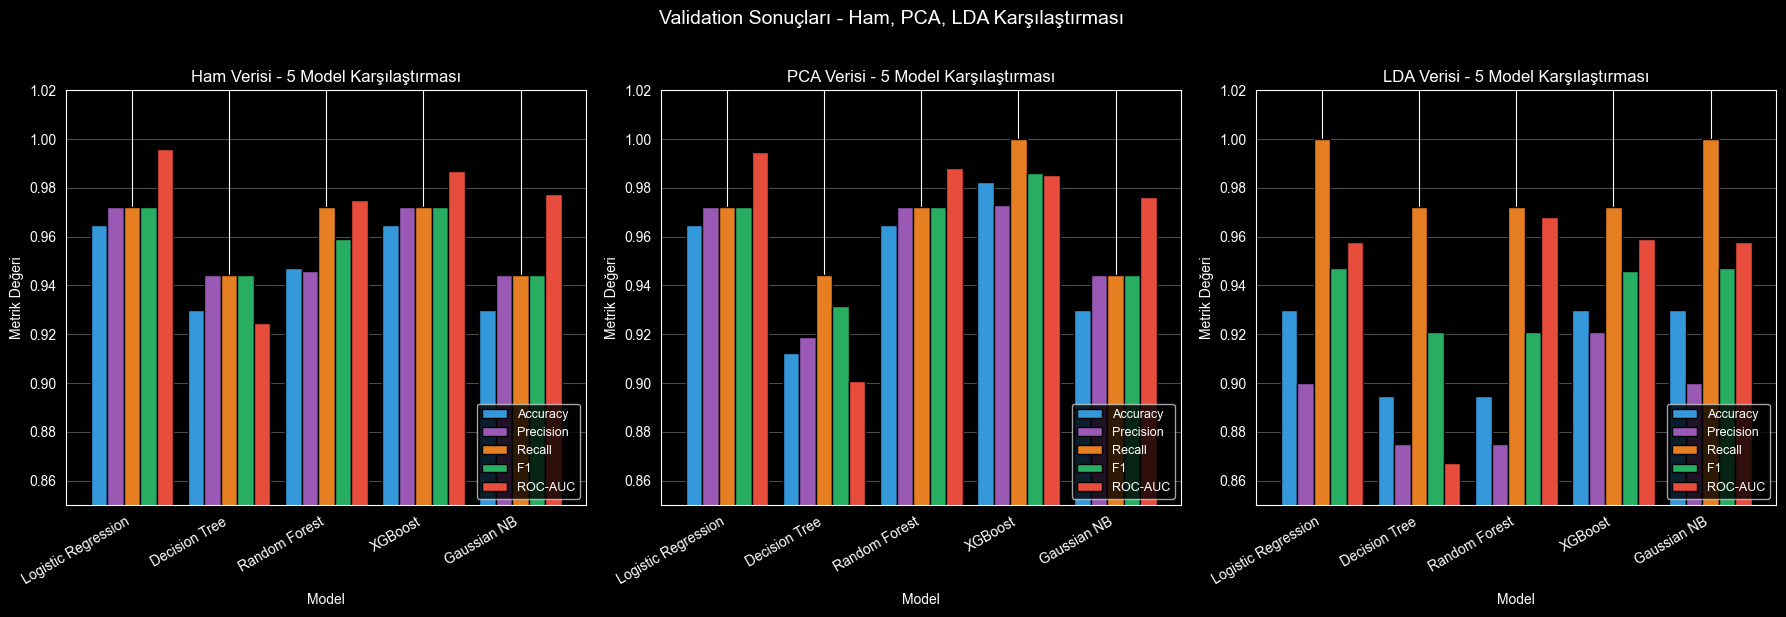

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
representations = ["Ham", "PCA", "LDA"]
colors_metric = ["#3498db", "#9b59b6", "#e67e22", "#27ae60", "#e74c3c"]

for ax, repr_name in zip(axes, representations):
    subset = results_df[results_df["Veri"] == repr_name].set_index("Model")
    subset[metrics_to_plot].plot(kind="bar", ax=ax, color=colors_metric,
                                   edgecolor="black", width=0.85)
    ax.set_title(f"{repr_name} Verisi - 5 Model Karşılaştırması", fontsize=12)
    ax.set_ylabel("Metrik Değeri")
    ax.set_ylim([0.85, 1.02])
    ax.legend(loc="lower right", fontsize=9)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Validation Sonuçları - Ham, PCA, LDA Karşılaştırması", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [46]:
# F1'e göre en iyi modelin bulunması
best_idx = results_df["F1"].idxmax()
best_row = results_df.iloc[best_idx]

print("F1-Score Üzerinden En İyi Model:")
print(f'Model:            {best_row["Model"]}')
print(f'Veri Temsili:     {best_row["Veri"]}')
print(f'Accuracy:         {best_row["Accuracy"]:.4f}')
print(f'Precision:        {best_row["Precision"]:.4f}')
print(f'Recall:           {best_row["Recall"]:.4f}')
print(f'F1-Score:         {best_row["F1"]:.4f}')
print(f'ROC-AUC:          {best_row["ROC-AUC"]:.4f}')

# En iyi değişkeninin oluşturulması
best_model_name = best_row["Model"]
best_repr = best_row["Veri"]
best_model = trained_models[best_repr][best_model_name]


F1-Score Üzerinden En İyi Model:
Model:            XGBoost
Veri Temsili:     PCA
Accuracy:         0.9825
Precision:        0.9730
Recall:           1.0000
F1-Score:         0.9863
ROC-AUC:          0.9854


'En İyi Modelin Test Datasında Çalıştırılması

In [47]:
from sklearn.metrics import confusion_matrix, classification_report

X_test_best = data_representations[best_repr]["X_test"]
test_metrics = evaluate_model(best_model, X_test_best, y_test)

print(f"En iyi modelin test veri performansı: ({best_model_name} - {best_repr}) ")
for metric, value in test_metrics.items():
    print(f"  {metric:10s}: {value:.4f}")

print(" ")
print("Validasyon Sonuçları ile Karşılaştırma:")
val_row = results_df[(results_df["Model"]==best_model_name) & (results_df["Veri"]==best_repr)].iloc[0]
print(f'{"Metrik":<12s} {"Validation":<12s} {"Test":<12s} {"Fark":<10s}')

for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    v = val_row[metric]
    t = test_metrics[metric]
    diff = t - v
    print(f"{metric:<12s} {v:<12.4f} {t:<12.4f} {diff:+.4f}")

En iyi modelin test veri performansı: (XGBoost - PCA) 
  Accuracy  : 0.9386
  Precision : 0.9577
  Recall    : 0.9444
  F1        : 0.9510
  ROC-AUC   : 0.9917
 
Validasyon Sonuçları ile Karşılaştırma:
Metrik       Validation   Test         Fark      
Accuracy     0.9825       0.9386       -0.0439
Precision    0.9730       0.9577       -0.0152
Recall       1.0000       0.9444       -0.0556
F1           0.9863       0.9510       -0.0353
ROC-AUC      0.9854       0.9917       +0.0063


Confusion Matrixin Oluşturulması

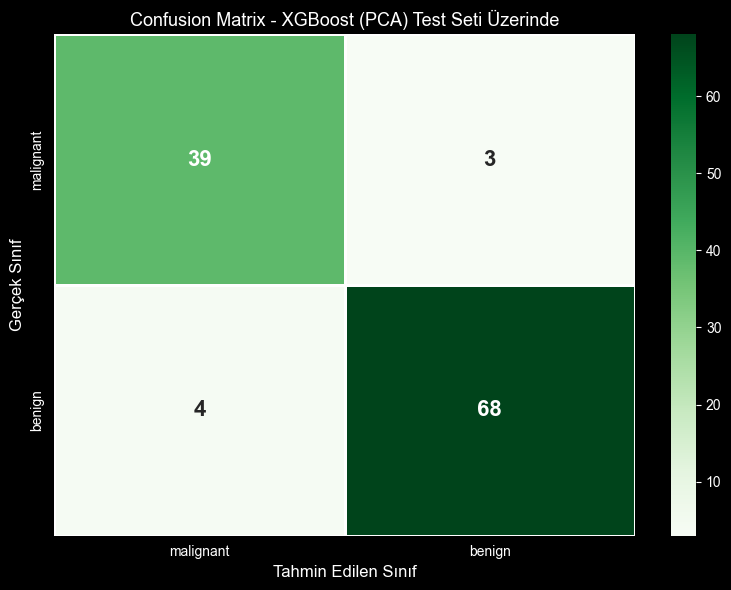

In [48]:
y_test_pred = best_model.predict(X_test_best)
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap="Greens", cbar=True,
            xticklabels=["malignant", "benign"],
            yticklabels=["malignant", "benign"],
            linewidths=2, linecolor="white",
            annot_kws={"size": 16, "weight": "bold"},
            ax=ax)
ax.set_xlabel("Tahmin Edilen Sınıf", fontsize=12)
ax.set_ylabel("Gerçek Sınıf", fontsize=12)
ax.set_title(f"Confusion Matrix - {best_model_name} ({best_repr}) Test Seti Üzerinde", fontsize=13)

plt.tight_layout()
plt.show()

ROC Eğrisi

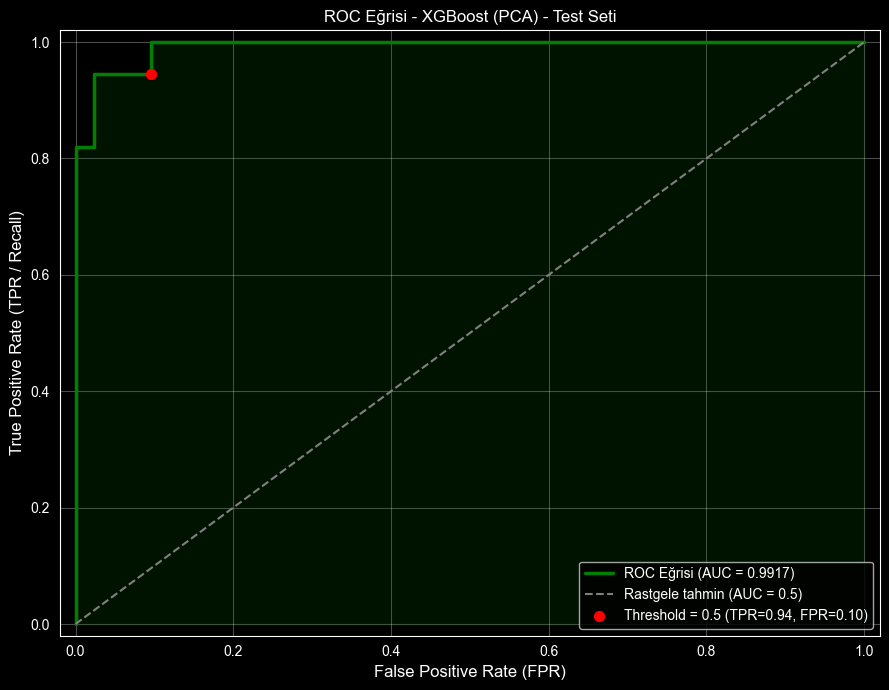

In [49]:
from sklearn.metrics import roc_curve, auc

# Pozitif sınıf olasılıkları
if hasattr(best_model, "predict_proba"):
    y_test_proba = best_model.predict_proba(X_test_best)[:, 1]
else:
    y_test_proba = best_model.decision_function(X_test_best)

# ROC noktalarını hesaplanması
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(fpr, tpr, color="green", lw=2.5, label=f"ROC Eğrisi (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Rastgele tahmin (AUC = 0.5)")

threshold_05_idx = np.argmin(np.abs(thresholds - 0.5))
ax.scatter(fpr[threshold_05_idx], tpr[threshold_05_idx], color='red', s=50, zorder=5,
           label=f"Threshold = 0.5 (TPR={tpr[threshold_05_idx]:.2f}, FPR={fpr[threshold_05_idx]:.2f})")

ax.fill_between(fpr, tpr, alpha=0.15, color='green')
ax.set_xlabel("False Positive Rate (FPR)", fontsize=12)
ax.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=12)
ax.set_title(f"ROC Eğrisi - {best_model_name} ({best_repr}) - Test Seti", fontsize=12)
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
plt.tight_layout()
plt.show()

Threshold Etkisi:
 Threshold  TN  FP  FN  TP  Precision  Recall     F1
       0.1  38   4   1  71     0.9467  0.9861 0.9660
       0.2  38   4   2  70     0.9459  0.9722 0.9589
       0.3  38   4   4  68     0.9444  0.9444 0.9444
       0.4  38   4   4  68     0.9444  0.9444 0.9444
       0.5  39   3   4  68     0.9577  0.9444 0.9510
       0.6  39   3   4  68     0.9577  0.9444 0.9510
       0.7  40   2   4  68     0.9714  0.9444 0.9577
       0.8  41   1   4  68     0.9855  0.9444 0.9645
       0.9  41   1   4  68     0.9855  0.9444 0.9645


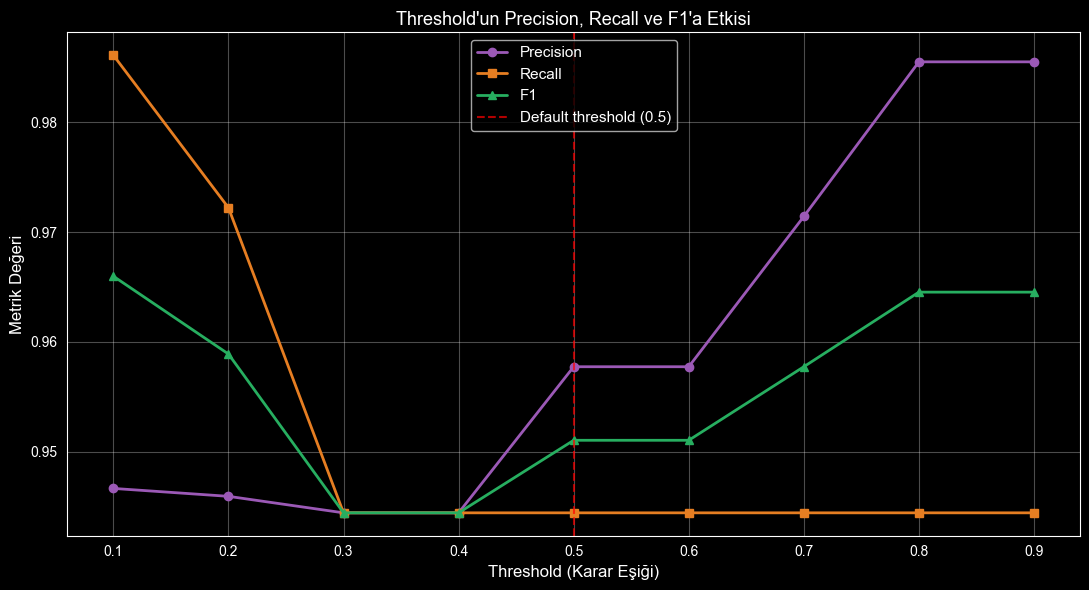

In [50]:
# Farklı threshold'larda metrik hesaplama
threshold_analysis = []
for thr in np.arange(0.1, 1.0, 0.1):
    y_pred_thr = (y_test_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thr).ravel()
    threshold_analysis.append({
        "Threshold": round(thr, 2),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": tp / (tp+fp) if (tp+fp)>0 else 0,
        "Recall": tp / (tp+fn) if (tp+fn)>0 else 0,
        "F1": (2*tp / (2*tp+fp+fn)) if (2*tp+fp+fn)>0 else 0
    })

threshold_df = pd.DataFrame(threshold_analysis)
print("Threshold Etkisi:")
print(threshold_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(threshold_df["Threshold"], threshold_df["Precision"], "o-", label="Precision", color="#9b59b6", lw=2)
ax.plot(threshold_df["Threshold"], threshold_df["Recall"], "s-", label="Recall", color="#e67e22", lw=2)
ax.plot(threshold_df["Threshold"], threshold_df["F1"], "^-", label="F1", color="#27ae60", lw=2)
ax.axvline(x=0.5, color="red", linestyle='--', alpha=0.7, label="Default threshold (0.5)")
ax.set_xlabel("Threshold (Karar Eşiği)", fontsize=12)
ax.set_ylabel("Metrik Değeri", fontsize=12)
ax.set_title(f"Threshold\'un Precision, Recall ve F1\'a Etkisi", fontsize=13)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

SHAP kütüphanesi ve En İyi Model SHAP Analizi (PCA)

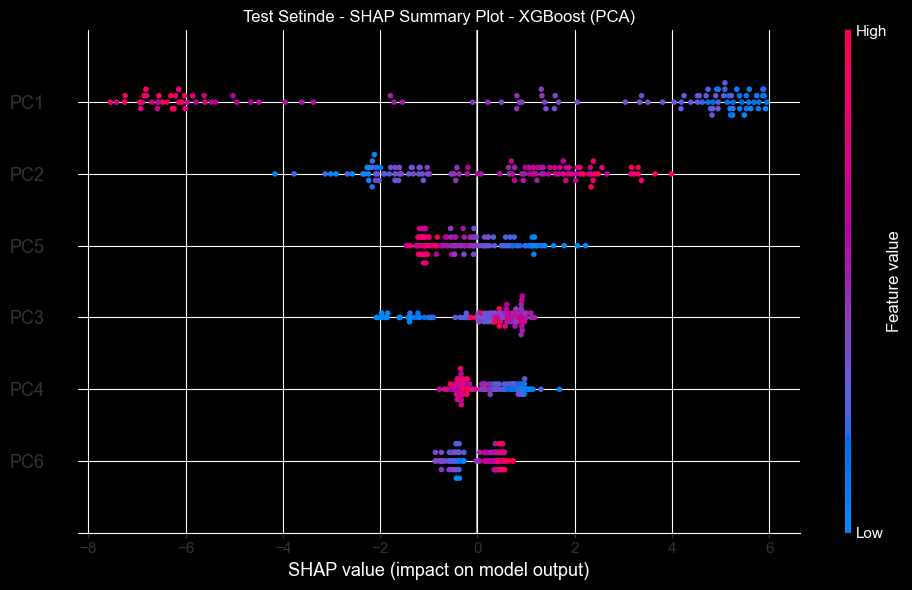

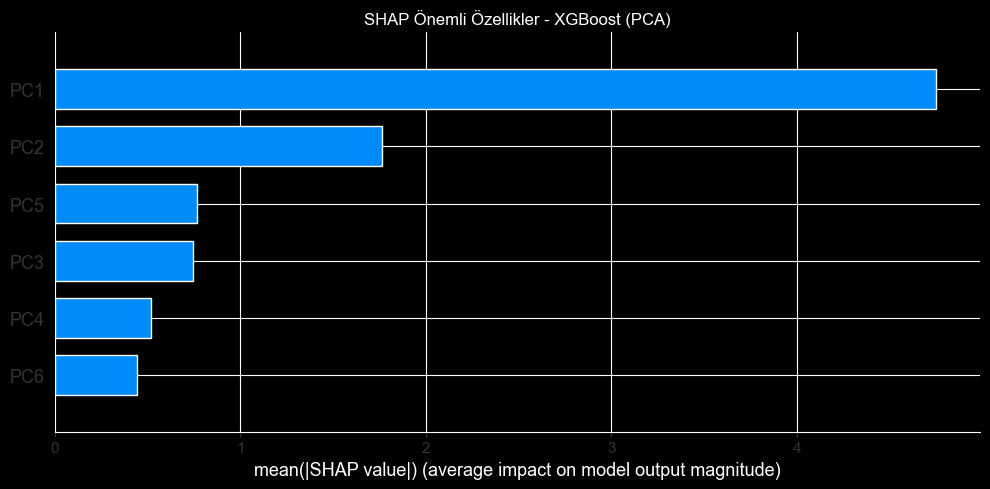

In [51]:
import shap
import tqdm as notebook_tqdm

# SHAP'ı TreeExplainer ile best model için kur (XGBoost + PCA)
explainer = shap.TreeExplainer(best_model)

# Test setinde PCA verisi üzerinde SHAP değerleri hesapla
X_test_pca_array = X_test_pca if isinstance(X_test_pca, np.ndarray) else X_test_pca.values
shap_values = explainer.shap_values(X_test_pca_array)

pca_feature_names = [f"PC{i+1}" for i in range(X_test_pca_array.shape[1])]

# Summary plot - dot plot
shap.summary_plot(shap_values, X_test_pca_array, feature_names=pca_feature_names,
                   show=False, plot_size=(10, 6))
plt.title(f"Test Setinde - SHAP Summary Plot - {best_model_name} ({best_repr})", fontsize=12)
plt.tight_layout()
plt.show()
print()

# Bar plot
shap.summary_plot(shap_values, X_test_pca_array, feature_names=pca_feature_names,
                   plot_type="bar", show=False, plot_size=(10, 5))
plt.title(f"SHAP Önemli Özellikler - {best_model_name} ({best_repr})", fontsize=12)
plt.tight_layout()
plt.show()

In [52]:
def get_shap_values(model, X_train, X_test, model_name):
    if model_name == 'Logistic Regression':
        explainer = shap.LinearExplainer(model, X_train)
        sv = explainer.shap_values(X_test)
    elif model_name == 'Gaussian NB':
        bg = X_train[:50] if len(X_train) > 50 else X_train
        explainer = shap.KernelExplainer(
            lambda x: model.predict_proba(x)[:, 1], bg, silent=True)
        sv = explainer.shap_values(X_test, nsamples=100, silent=True)
    else:
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_test)
        if isinstance(sv, list):
            sv = sv[1]
        if hasattr(sv, 'shape') and len(sv.shape) == 3:
            sv = sv[:, :, 1]
    return sv

# 15 model için SHAP değerlerini hesapla
all_shap = {}
for repr_name, repr_data in data_representations.items():
    for model_name, model in trained_models[repr_name].items():
        sv = get_shap_values(model, repr_data['X_train'], repr_data['X_test'], model_name)
        all_shap[(repr_name, model_name)] = sv
        print(f'{repr_name} - {model_name}: OK')

Ham - Logistic Regression: OK
Ham - Decision Tree: OK
Ham - Random Forest: OK
Ham - XGBoost: OK
Ham - Gaussian NB: OK
PCA - Logistic Regression: OK
PCA - Decision Tree: OK
PCA - Random Forest: OK
PCA - XGBoost: OK
PCA - Gaussian NB: OK
LDA - Logistic Regression: OK
LDA - Decision Tree: OK
LDA - Random Forest: OK
LDA - XGBoost: OK
LDA - Gaussian NB: OK


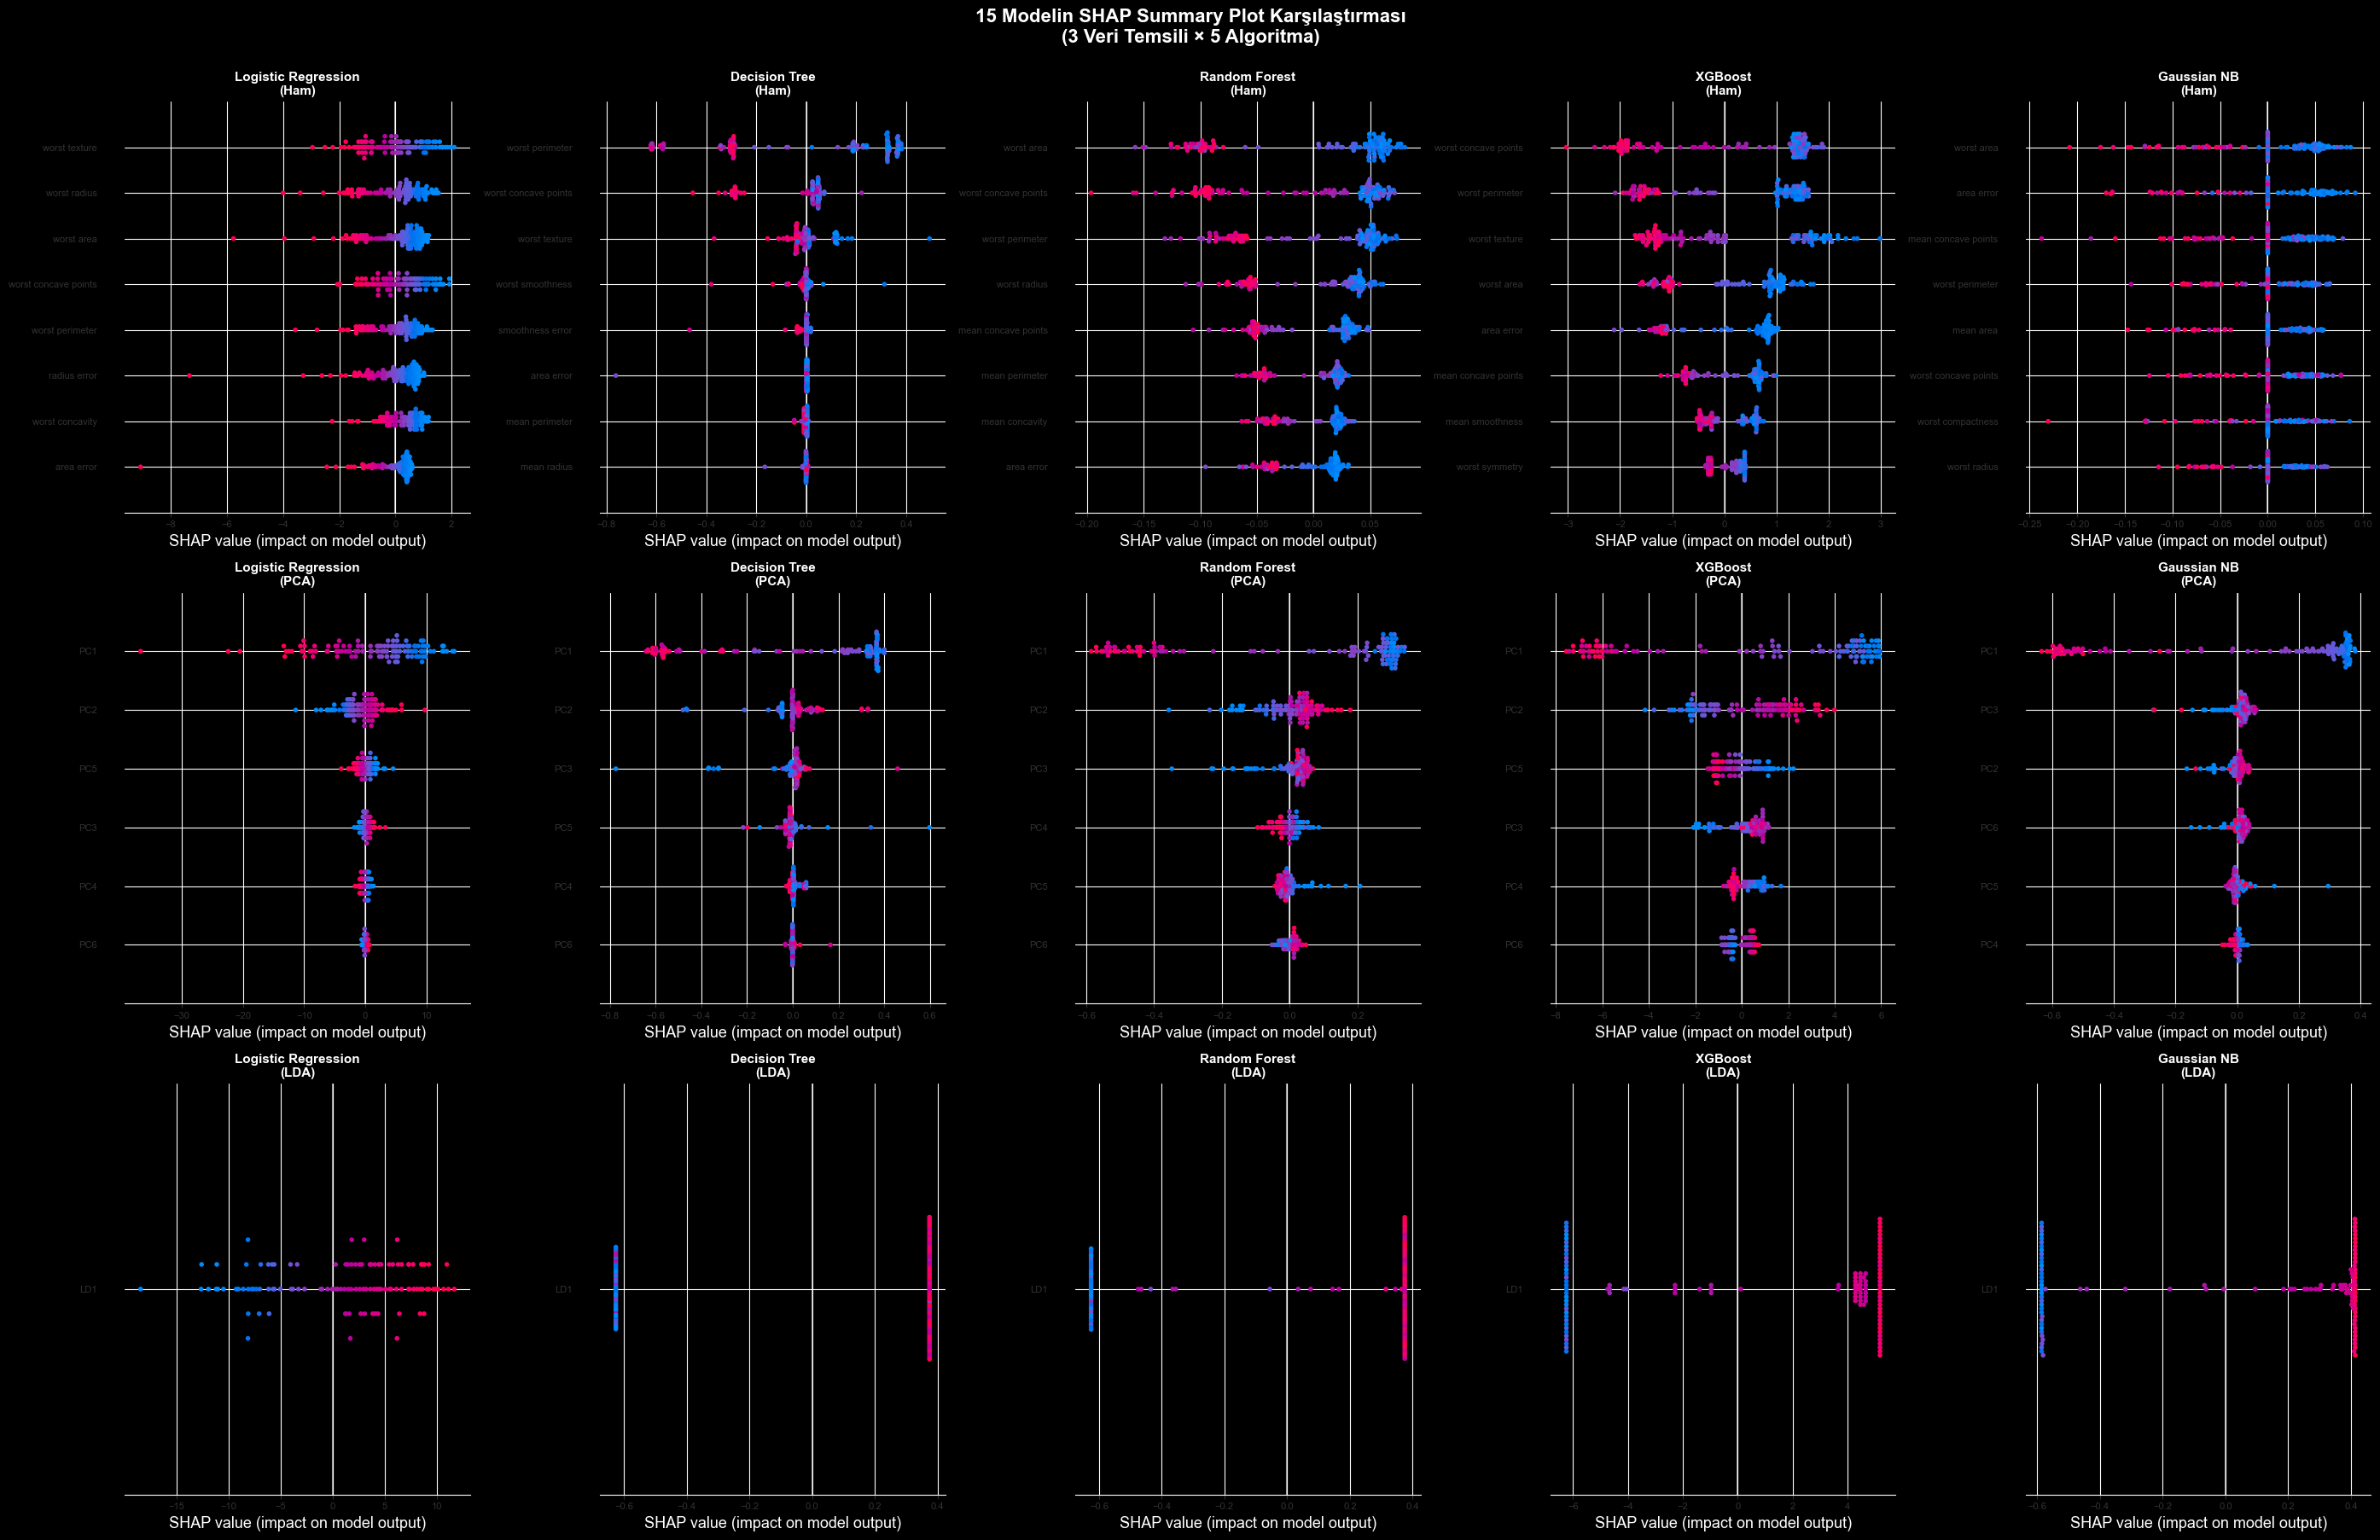

In [53]:
feature_names_dict = {
    'Ham': list(X.columns),
    'PCA': [f'PC{i+1}' for i in range(X_test_pca.shape[1])],
    'LDA': ['LD1']
}

X_test_dict = {
    'Ham': X_test_scaled,
    'PCA': X_test_pca,
    'LDA': X_test_lda
}

algorithms = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'Gaussian NB']
representations = ['Ham', 'PCA', 'LDA']

fig, axes = plt.subplots(3, 5, figsize=(28, 18))

for i, repr_name in enumerate(representations):
    for j, model_name in enumerate(algorithms):
        ax = axes[i, j]
        plt.sca(ax)

        sv = all_shap[(repr_name, model_name)]
        X_te = X_test_dict[repr_name]
        feats = feature_names_dict[repr_name]
        max_disp = min(8, len(feats))

        shap.summary_plot(
            sv, X_te,
            feature_names=feats,
            max_display=max_disp,
            show=False,
            plot_size=None,
            color_bar=False
        )

        ax.set_title(f'{model_name}\n({repr_name})', fontsize=11, fontweight='bold')
        ax.tick_params(axis='y', labelsize=8)
        ax.tick_params(axis='x', labelsize=8)

plt.suptitle('15 Modelin SHAP Summary Plot Karşılaştırması\n(3 Veri Temsili × 5 Algoritma)',
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

In [54]:
#SHAP değerlerini hesapla
mean_abs_shap = np.abs(shap_values).mean(axis=0)

imp_pca = pd.DataFrame({
    "Bileşen": pca_feature_names,
    "Mean SHAP": mean_abs_shap
}).sort_values("Mean SHAP", ascending=False)

print("PCA Bileşenlerinin SHAP Önemi:")
print(imp_pca.round(4).to_string(index=False))

PCA Bileşenlerinin SHAP Önemi:
Bileşen  Mean SHAP
    PC1     4.7484
    PC2     1.7625
    PC5     0.7684
    PC3     0.7432
    PC4     0.5172
    PC6     0.4431


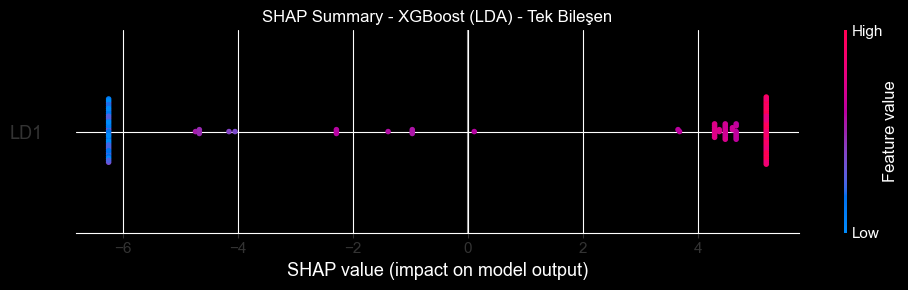

LDA - LD1 SHAP değer aralığı:
  Min: -6.242
  Max: 5.185
  Ortalama mutlak: 4.996


In [55]:
xgb_lda = trained_models["LDA"]["XGBoost"]
X_test_lda_array = X_test_lda if isinstance(X_test_lda, np.ndarray) else X_test_lda.values

explainer_lda = shap.TreeExplainer(xgb_lda)
shap_values_lda = explainer_lda.shap_values(X_test_lda_array)

shap.summary_plot(shap_values_lda, X_test_lda_array,
                   feature_names=["LD1"],
                   show=False, plot_size=(10, 3))
plt.title("SHAP Summary - XGBoost (LDA) - Tek Bileşen", fontsize=12)
plt.tight_layout()
plt.show()

print(f"LDA - LD1 SHAP değer aralığı:")
print(f"  Min: {shap_values_lda.min():.3f}")
print(f"  Max: {shap_values_lda.max():.3f}")
print(f"  Ortalama mutlak: {np.abs(shap_values_lda).mean():.3f}")